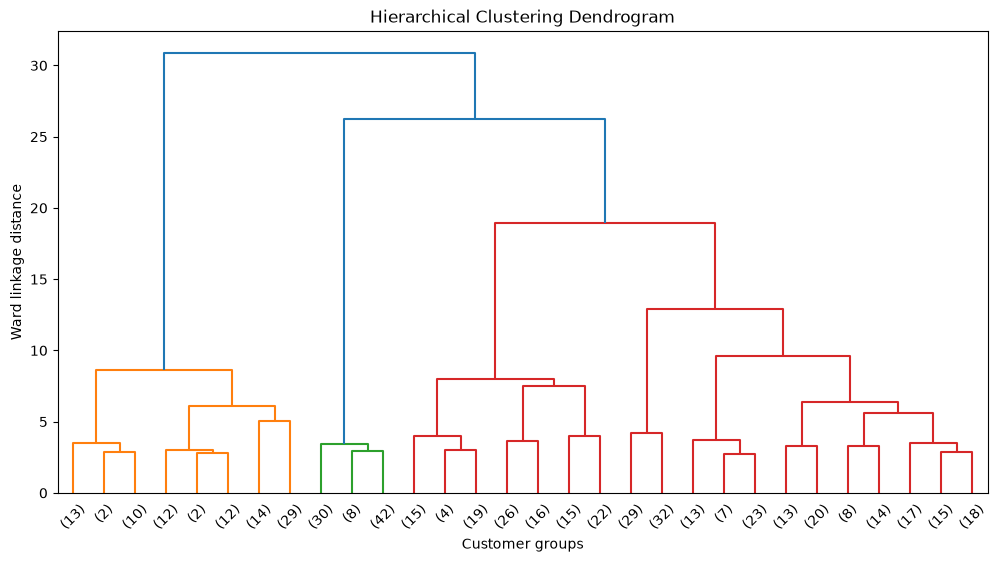

Number of clusters: 4
Silhouette Score: 0.31416238586611056
               Age  Annual Income  Spending Score
Cluster                                          
0        30.306220   57582.014354       66.765550
1        50.457447  118964.212766       25.872340
2        24.662500   27926.125000       21.375000
3        40.487179  101929.769231       78.700855


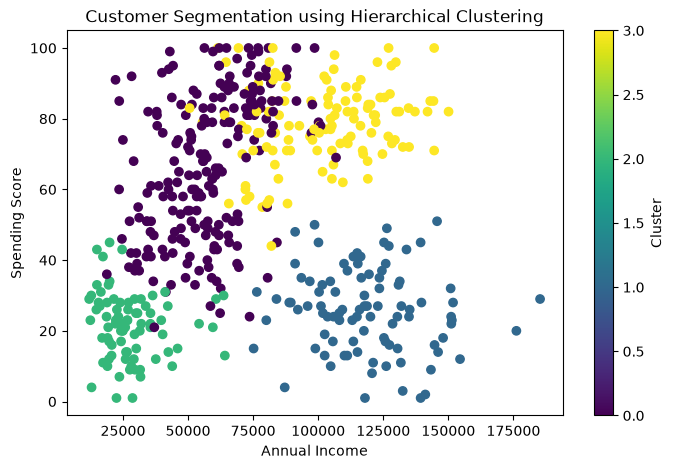

In [2]:

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

from scipy.cluster.hierarchy import (
    linkage,
    dendrogram
)

# 1. Load customer dataset
df = pd.read_csv("customers.csv")

# 2. Select numerical features
features = [
    "Age",
    "Annual Income",
    "Spending Score"
]

X = df[features].dropna()

# 3. Scale features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Create linkage matrix for dendrogram
Z = linkage(
    X_scaled,
    method="ward",
    metric="euclidean"
)

# 5. Plot dendrogram
plt.figure(figsize=(12, 6))

dendrogram(
    Z,
    truncate_mode="lastp",
    p=30,
    show_leaf_counts=True
)

plt.title("Hierarchical Clustering Dendrogram")
plt.xlabel("Customer groups")
plt.ylabel("Ward linkage distance")
plt.show()

# 6. Apply Agglomerative Clustering
optimal_k = 4

model = AgglomerativeClustering(
    n_clusters=optimal_k,
    metric="euclidean",
    linkage="ward"
)

labels = model.fit_predict(X_scaled)

# 7. Attach cluster labels
df_clustered = df.loc[X.index].copy()
df_clustered["Cluster"] = labels

# 8. Evaluate clustering
print("Number of clusters:", optimal_k)

print(
    "Silhouette Score:",
    silhouette_score(X_scaled, labels)
)

# 9. Analyze cluster characteristics
print(
    df_clustered.groupby("Cluster")[features].mean()
)

# 10. Visualize customer segments
plt.figure(figsize=(8, 5))

plt.scatter(
    df_clustered["Annual Income"],
    df_clustered["Spending Score"],
    c=labels,
    cmap="viridis"
)

plt.xlabel("Annual Income")
plt.ylabel("Spending Score")
plt.title("Customer Segmentation using Hierarchical Clustering")
plt.colorbar(label="Cluster")
plt.show()
